# ML Practical 2
### Name: Taher Sanawadwala
### Section: A-A3
### Roll No: 46

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv('USA_Housing.csv')
df.head()

,Area Income,Area House Age,Area No of Rooms,Area No of Bedrooms,Area Population,Price
0,79545.45857,5.682861,7.009188,4.09,23086.80050,1.059034e+06
1,79248.64245,6.002900,6.730821,3.09,40173.07217,1.505891e+06
2,61287.06718,5.865890,8.512727,5.13,36882.15940,1.058988e+06
3,63345.24005,7.188236,5.586729,3.26,34310.24283,1.260617e+06
4,59982.19723,5.040555,7.839388,4.23,26354.10947,6.309435e+05


In [3]:
df.tail()

,Area Income,Area House Age,Area No of Rooms,Area No of Bedrooms,Area Population,Price
4995,60567.94414,7.830362,6.137356,3.46,22837.36103,1060193.786
4996,78491.27543,6.999135,6.576763,4.02,25616.11549,1482617.729
4997,63390.68689,7.250591,4.805081,2.13,33266.14549,1030729.583
4998,68001.33124,5.534388,7.130144,5.44,42625.62016,1198656.872
4999,65510.58180,5.992305,6.792336,4.07,46501.28380,1298950.480


In [4]:
df.isnull().sum()

Area Income            0
Area House Age         0
Area No of Rooms       0
Area No of Bedrooms    0
Area Population        0
Price                  0
dtype: int64

In [5]:
pd.set_option('display.float_format', '{:.2f}'.format)

In [6]:
df.head()

,Area Income,Area House Age,Area No of Rooms,Area No of Bedrooms,Area Population,Price
0,79545.46,5.68,7.01,4.09,23086.80,1059033.56
1,79248.64,6.00,6.73,3.09,40173.07,1505890.92
2,61287.07,5.87,8.51,5.13,36882.16,1058987.99
3,63345.24,7.19,5.59,3.26,34310.24,1260616.81
4,59982.20,5.04,7.84,4.23,26354.11,630943.49


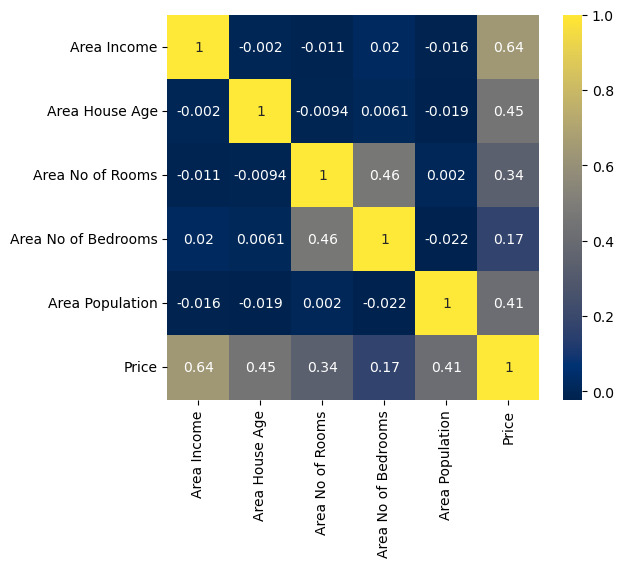

In [7]:
#Multivariate Analysis
plt.figure(figsize=(6,5))

numeric_df = df.select_dtypes(include=['number'])

sns.heatmap(numeric_df.corr(),
            annot=True,
            cmap='cividis')

plt.show()

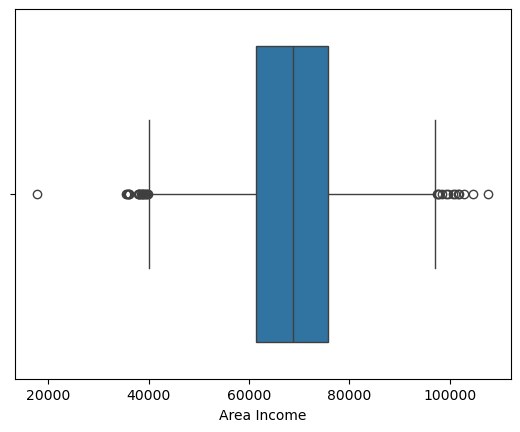

In [8]:
sns.boxplot(x=df["Area Income"])
plt.show()

In [9]:
#Remove Outliers using IQR Model
Q1 = df["Area Income"].quantile(0.25)
Q3 = df["Area Income"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR

df = df[(df["Area Income"] >= lower) & (df["Area Income"] <= upper)]

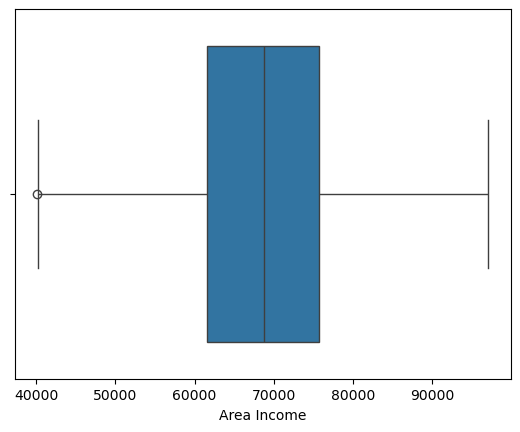

In [10]:
sns.boxplot(x=df["Area Income"])
plt.show()

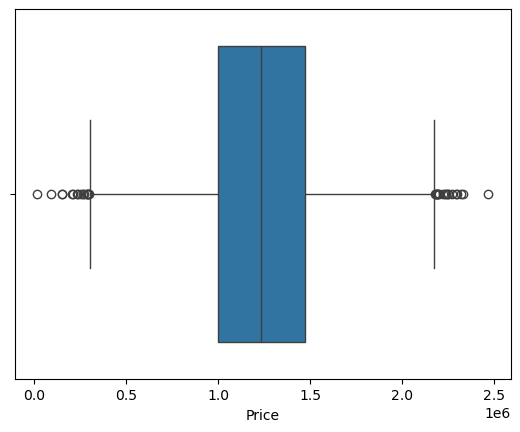

In [11]:
sns.boxplot(x=df["Price"])
plt.show()

In [12]:
#Remove Outliers using IQR Model
Q1 = df["Price"].quantile(0.25)
Q3 = df["Price"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR

df = df[(df["Price"] >= lower) & (df["Price"] <= upper)]

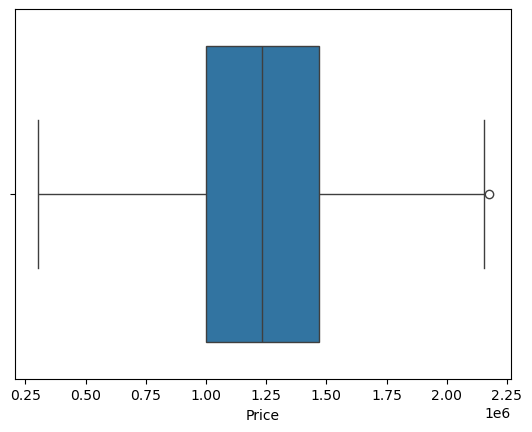

In [13]:
sns.boxplot(x=df["Price"])
plt.show()

# SLR

In [14]:
X = df[['Area Income']]
y = df['Price']

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)

In [16]:
slr_model = LinearRegression()

slr_model.fit(X_train, y_train)

LinearRegression()

In [17]:
y_pred = slr_model.predict(X_test)

In [18]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.metrics import root_mean_squared_error

print("Simple Linear Regression Results")
print("--------------------------------")

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

Simple Linear Regression Results
--------------------------------
MAE: 216087.71436287294
MSE: 70880962069.43341
RMSE: 266234.78748922615
R2 Score: 0.3983053580016537


In [19]:
print("Intercept:", slr_model.intercept_)
print("Slope:", slr_model.coef_[0])

Intercept: -174255.61111272033
Slope: 20.47908507410674


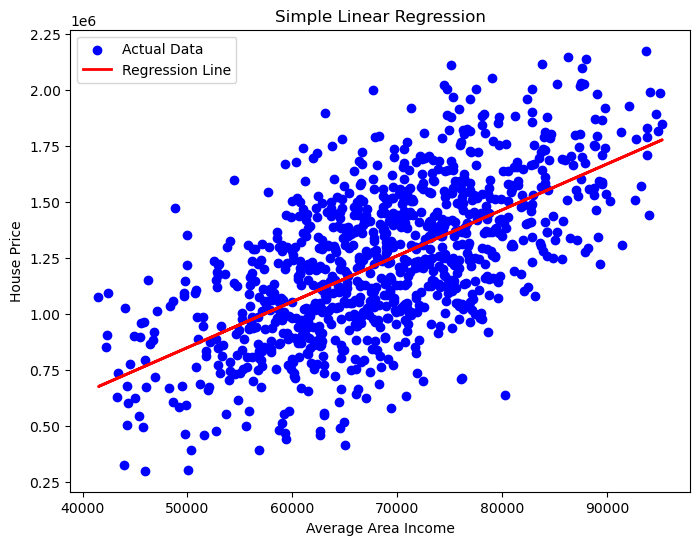

In [20]:
plt.figure(figsize=(8,6))

plt.scatter(X_test, y_test, color='blue', label='Actual Data')

plt.plot(X_test,y_pred,color='red', linewidth=2, label='Regression Line')

plt.xlabel("Average Area Income")
plt.ylabel("House Price")
plt.title("Simple Linear Regression")
plt.legend()

plt.show()

In [21]:
income = float(input("Enter Average Area Income: "))

new_data = np.array([[income]])

prediction = slr_model.predict(new_data)

print("Predicted House Price = ${:,.2f}".format(prediction[0]))

Enter Average Area Income:  10000


Predicted House Price = $30,535.24


# MLR

In [22]:
X = df.drop(["Price"], axis=1)
y = df['Price']

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)

In [24]:
mlr = LinearRegression()

mlr.fit(X_train, y_train)

LinearRegression()

In [25]:
coef = pd.DataFrame(
    mlr.coef_,
    X.columns,
    columns = ["Coefficient"])

coef

,Coefficient
Area Income,21.53
Area House Age,165086.64
Area No of Rooms,121071.09
Area No of Bedrooms,1327.60
Area Population,14.98


In [26]:
y_pred = mlr.predict(X_test)

In [27]:
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 78456.94223617997
MSE: 9643840323.221422
RMSE: 98203.05658797704
R2 Score: 0.9181353232044764


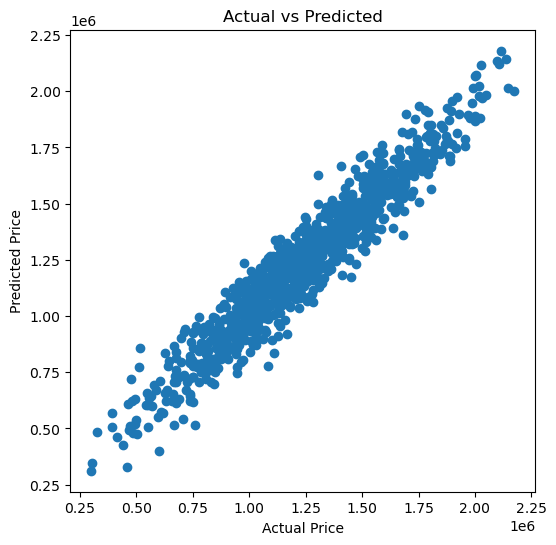

In [29]:
plt.figure(figsize=(6,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")

plt.ylabel("Predicted Price")

plt.title("Actual vs Predicted")

plt.show()

In [33]:
# Take input from the user
income = float(input("Enter Average Area Income: "))
house_age = float(input("Enter Average Area House Age: "))
rooms = float(input("Enter Average Area Number of Rooms: "))
bedrooms = float(input("Enter Average Area Number of Bedrooms: "))
population = float(input("Enter Area Population: "))
test_input = np.array([[income, house_age, rooms, bedrooms, population]])

predicted_price = mlr.predict(test_input)

print("\nPredicted House Price: ${:,.2f}".format(predicted_price[0]))

Enter Average Area Income:  10000
Enter Average Area House Age:  10
Enter Average Area Number of Rooms:  4
Enter Average Area Number of Bedrooms:  700
Enter Area Population:  20000



Predicted House Price: $953,629.67


# Ridge Regression

In [48]:
from sklearn.model_selection import GridSearchCV

In [49]:
from sklearn.linear_model import Ridge

ridge = Ridge()

ridge.fit(X_train, y_train)

ridge_pred = ridge.predict(X_test)

print("Default Ridge R2 : ", r2_score(y_test, ridge_pred))

Default Ridge R2 :  0.9181377871733089


In [50]:
param_grid = {'alpha': [0.001,0.01,0.1,1,10,100]}

In [60]:
grid_ridge = GridSearchCV(estimator=Ridge(),param_grid = param_grid,
                         scoring = 'r2',
                         cv=5)

In [61]:
grid_ridge.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=Ridge(),
             param_grid={'alpha': [0.001, 0.01, 0.1, 1, 10, 100]},
             scoring='r2')

In [62]:
print("Best Alpha :", grid_ridge.best_params_)

Best Alpha : {'alpha': 1}


In [63]:
print(grid_ridge.best_score_)

0.9103899646029898


In [64]:
best_ridge = grid_ridge.best_estimator_

ridge_pred = best_ridge.predict(X_test)

In [66]:
print("MAE:", mean_absolute_error(y_test, ridge_pred))
print("MSE:", mean_squared_error(y_test, ridge_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, ridge_pred)))
print("R2 Score:", r2_score(y_test, ridge_pred))

MAE: 78456.01212101862
MSE: 9643550062.233276
RMSE: 98201.5787155852
R2 Score: 0.9181377871733089


# Lasso Regression

In [67]:
from sklearn.linear_model import Lasso

param_grid = {'alpha': [0.001,0.01,0.1,1,10,100]}

In [68]:
grid_lasso = GridSearchCV(estimator=Lasso(max_iter=5000),param_grid = param_grid,cv=5,scoring='r2')

grid_lasso.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=Lasso(max_iter=5000),
             param_grid={'alpha': [0.001, 0.01, 0.1, 1, 10, 100]},
             scoring='r2')

In [69]:
print(grid_lasso.best_params_)

{'alpha': 0.001}


In [71]:
lasso_pred = grid_lasso.predict(X_test)

print(r2_score(y_test, lasso_pred))

0.9181353232593527
